In [79]:
import numpy as np
import matplotlib.pyplot as plt

In [116]:
f_a = lambda x1, x2, x3, _: x1**2 + x2**2 + x3**2
df_a = lambda x1, x2, x3, _: np.array([2*x1, 2*x2, 2*x3, 0])
f_b = lambda x1, x2, x3, x4: x1**2 + x2**2 + x3**2 + x4**2
df_b = lambda x1, x2, x3, x4: np.array([2*x1, 2*x2, 2*x3, 2*x4])

T = 10
step = 0.1
x1 = np.array([0.1, 0.1, 0.1, 0.1], dtype=float)
x2 = np.array([15, -20, 10, 10], dtype=float)
data = {"convex": [f_a, df_a], "strongly convex": [f_b, df_b]}

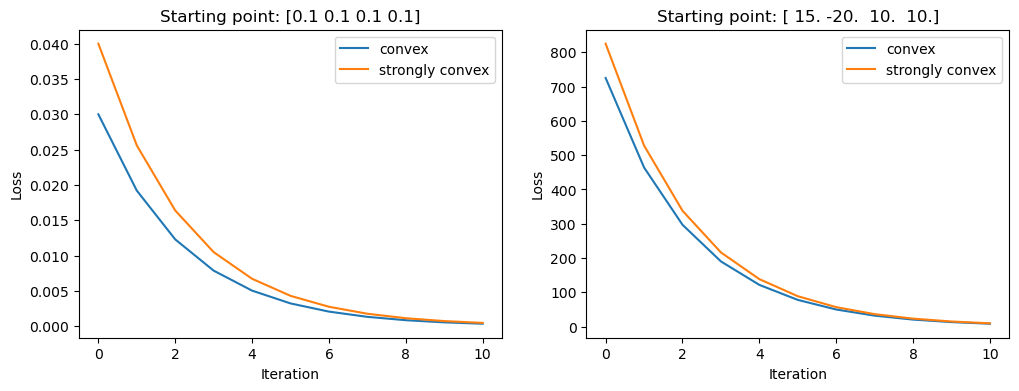

In [117]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

for label, (f, df) in data.items():
    for i, x in enumerate([x1.copy(), x2.copy()]):
        ax[i].set_xlabel("Iteration")
        ax[i].set_ylabel("Loss")
        ax[i].set_title(f"Starting point: {x}")
        
        losses = np.array([f(*x)])
        for _ in range(T):
            x -= step * df(*x)
            losses = np.append(losses, f(*x))
        ax[i].plot(losses, label=label)
        ax[i].legend()
        
plt.show()